In [23]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path
import scrapbook as sb

# Part 2

### 2.1 Parameters

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date

### 2.2: Data loading

In [3]:
conn = sqlite3.connect("data/data.db")

df = pd.read_sql_query(
    """
    SELECT *
    FROM ohlc_hw_cleaned
    WHERE ticker = ?
    AND ts BETWEEN ? AND ?
    ORDER BY ts
    """,
    conn,
    params=(ticker, start_date, end_date),
    parse_dates=["ts"]
)

conn.close()

In [4]:
# summary
n = len(df)
print(ticker, 'from', start_date, 'to', end_date,':', n, 'trading days')

# check that all rows have the correct ticker
print("All rows have correct ticker:", (df.loc[df["ticker"]==ticker,'ticker'].count() == n))

# first and last dates
print("first date:", df["ts"].min().date())
print("last date:", df["ts"].max().date())


# report if insufficient history
if n < 21:
    raise ValueError("insufficient history. At least 21 prices required.")

# first and last rows
display(df.head())
display(df.tail())

AAPL from 2024-01-01 to 2024-12-31 : 202 trading days
All rows have correct ticker: True
first date: 2024-01-02
last date: 2024-10-18


,ts,open,high,low,close,adj_close,volume,ticker,repair_flag
0,2024-01-02,187.15,188.44,183.89,185.64,184.94,82488674,AAPL,0
1,2024-01-03,184.22,185.88,183.43,184.25,183.55,58414460,AAPL,0
2,2024-01-04,182.15,183.09,180.88,181.91,181.22,71983570,AAPL,0
3,2024-01-05,181.99,182.76,180.17,181.18,180.50,62379661,AAPL,0
4,2024-01-08,182.09,185.60,181.50,185.56,184.86,59144470,AAPL,0


,ts,open,high,low,close,adj_close,volume,ticker,repair_flag
197,2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,AAPL,0
198,2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,AAPL,0
199,2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,AAPL,0
200,2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,AAPL,0
201,2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,AAPL,0


### 2.3 Calculate Risk Metrics


In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))

In [6]:
def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""
    return returns.rolling(window).std() * np.sqrt(252)

In [7]:
def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    cum_max = prices.cummax()
    drawdown = (prices - cum_max) / cum_max

    return drawdown

In [8]:
def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    returns = returns.dropna()

    if len(returns) < 20:
        return np.nan

    mean_return = returns.mean()
    std_return = returns.std()

    if pd.isna(std_return) or std_return == 0:
        return np.nan

    return (mean_return * 252 - risk_free_rate) / (std_return * np.sqrt(252))

In [9]:
# daily log returns using adjusted close
df["log_returns"] = calculate_returns(df["adj_close"])

# annualized 20-day rolling volatility
df["volatility_20d"] = calculate_volatility(df["log_returns"])

# drawdown using adjusted close
df["drawdown"] = calculate_max_drawdown(df["adj_close"])

# Calculate Sharpe ratio
sharpe = calculate_sharpe_ratio(df["log_returns"])

# Calculate maximum drawdown
max_drawdown = df["drawdown"].min()

In [10]:
# calculated metrics
display(df.tail())


print("sharpe ratio:", sharpe)
print("maximum drawdown:", max_drawdown)

,ts,open,high,low,close,adj_close,volume,ticker,repair_flag,log_returns,volatility_20d,drawdown
197,2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100,AAPL,0,0.016346,0.242503,-0.013856
198,2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400,AAPL,0,0.010964,0.243942,-0.002984
199,2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240,AAPL,0,-0.008891,0.241973,-0.011810
200,2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810,AAPL,0,0.001595,0.206097,-0.010232
201,2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281,AAPL,0,0.012202,0.209521,0.000000


sharpe ratio: 1.187256558320051
maximum drawdown: -0.15351779469245008


### 2.4 Visualization

In [11]:
# Helper columns for part 2.4

# 50 day moving average of adjusted close
df["ma_50"] = df["adj_close"].rolling(50).mean()

# mean rolling volatility 
mean_vol = df["volatility_20d"].mean()

# volatility regime for retrospective coloring
# gray = unavailable warm up, green = low/normal, red = high
df["vol_regime"] = np.where(
    df["volatility_20d"].isna(),
    "gray",
    np.where(df["volatility_20d"] > mean_vol, "high", "low"))

# colors for daily return bars
df["return_color"] = np.where(df["log_returns"] >= 0, "green", "red")

# locate maximum drawdown point
max_dd_idx = df["drawdown"].idxmin()
max_dd_date = df.loc[max_dd_idx, "ts"]
max_dd_value = df.loc[max_dd_idx, "drawdown"]


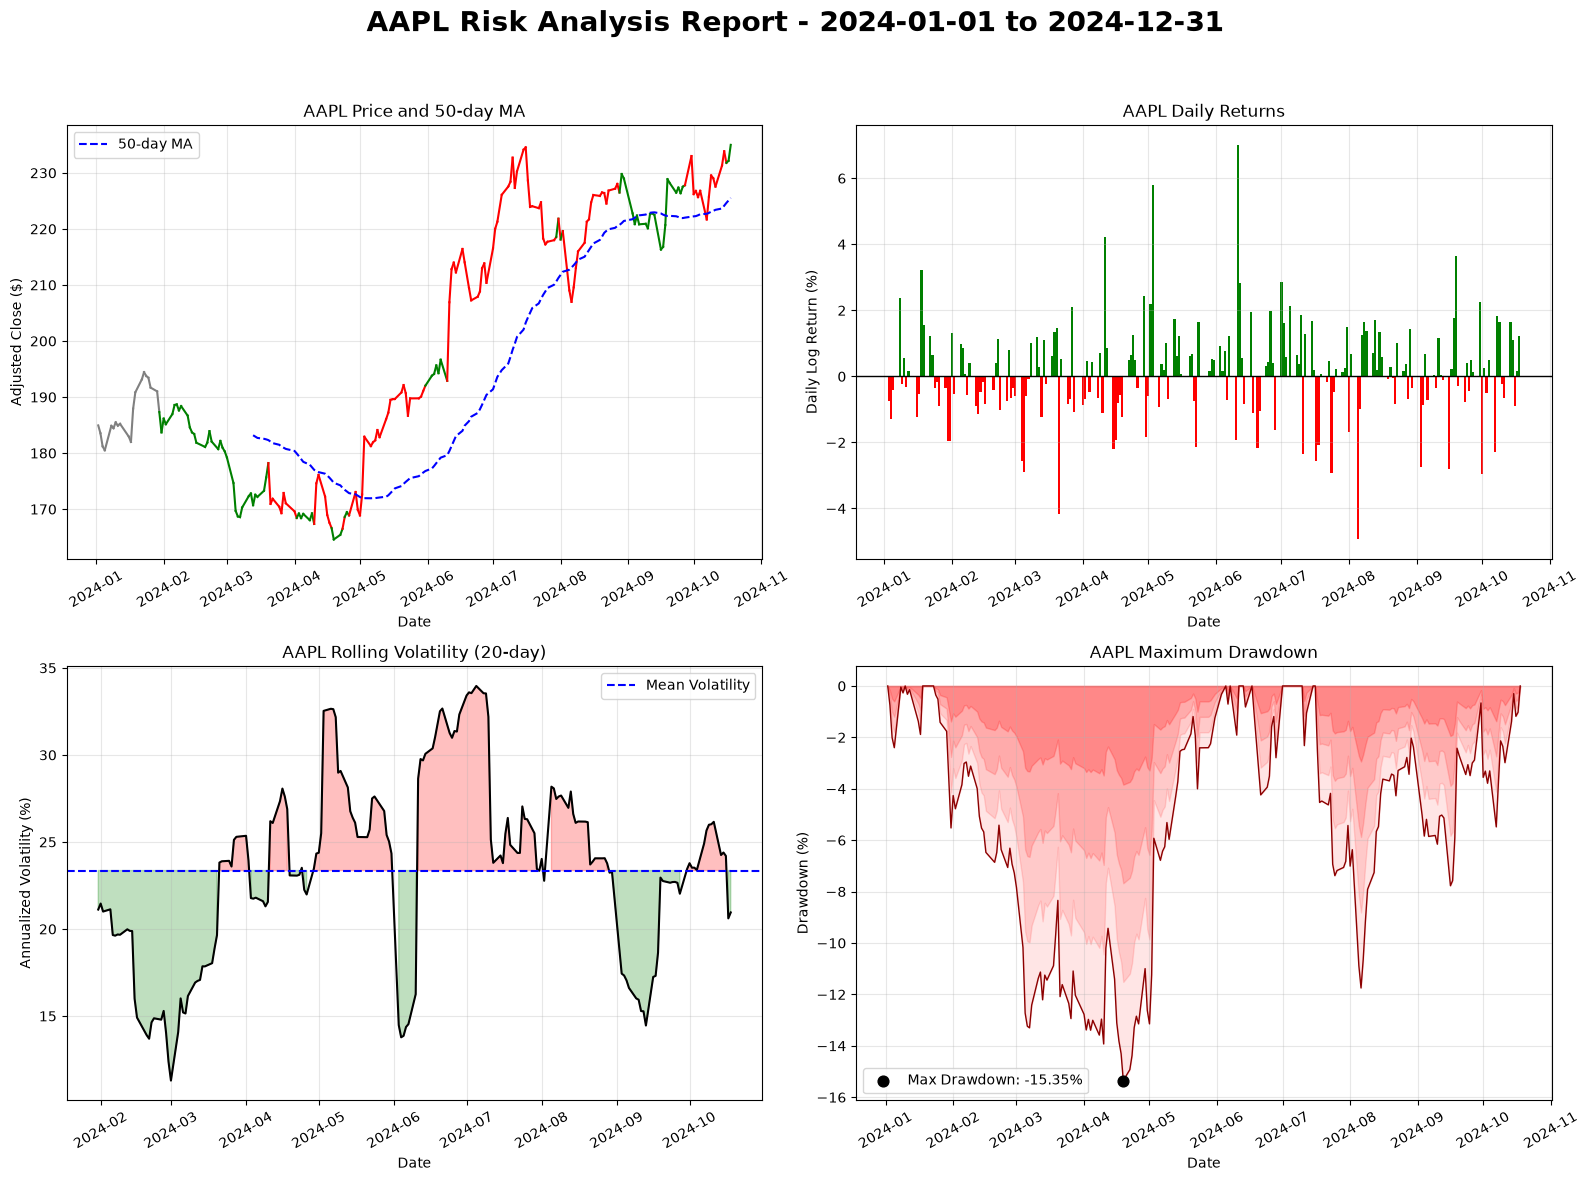

In [15]:
# creating 2 x 2 plot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

ax1 = axes[0, 0]  # Top left
ax2 = axes[0, 1]  # Top right
ax3 = axes[1, 0]  # Bottom left
ax4 = axes[1, 1]  # Bottom right



# Price chart, colored by volatility
for i in range(1, len(df)):
    regime = df["vol_regime"].iloc[i]

    if regime == "high":
        color = "red"
    elif regime == "low":
        color = "green"
    else:
        color = "gray"

    ax1.plot(
        df["ts"].iloc[i-1:i+1],
        df["adj_close"].iloc[i-1:i+1],
        color=color,
        linewidth=1.5
    )

# 50-day moving average
ax1.plot(df["ts"], df["ma_50"],
         color="blue", linestyle="--", label="50-day MA")

ax1.set_title(f"{ticker} Price and 50-day MA")
ax1.set_xlabel("Date")
ax1.set_ylabel("Adjusted Close ($)")
ax1.legend()




ax2.bar(
    df["ts"],
    df["log_returns"] * 100,
    color=df["return_color"],
    width=1
)

ax2.axhline(0, color="black", linewidth=1)

ax2.set_title(f"{ticker} Daily Returns")
ax2.set_xlabel("Date")
ax2.set_ylabel("Daily Log Return (%)")




vol = df["volatility_20d"]

# Rolling volatility line
ax3.plot(df["ts"], vol * 100, color="black", linewidth=1.5)

# Mean volatility
ax3.axhline(mean_vol * 100, color="blue",
            linestyle="--", label="Mean Volatility")

# Shade high and low volatility regions
ax3.fill_between(
    df["ts"], vol * 100, mean_vol * 100,
    where=vol > mean_vol,
    color="red", alpha=0.25
)

ax3.fill_between(
    df["ts"], vol * 100, mean_vol * 100,
    where=vol < mean_vol,
    color="green", alpha=0.25
)

ax3.set_title(f"{ticker} Rolling Volatility (20-day)")
ax3.set_xlabel("Date")
ax3.set_ylabel("Annualized Volatility (%)")
ax3.legend()




# Drawdown with layered transparent fills
for alpha, fraction in [(0.10, 1.0), (0.12, 0.75),
                        (0.15, 0.50), (0.20, 0.25)]:
    ax4.fill_between(
        df["ts"],
        df["drawdown"] * 100 * fraction,
        0,
        color="red",
        alpha=alpha
    )

# Drawdown line
ax4.plot(df["ts"], df["drawdown"] * 100,
         color="darkred", linewidth=1)

# Mark maximum drawdown
ax4.scatter(max_dd_date, max_dd_value * 100,
            color="black", s=60, zorder=5,
            label=f"Max Drawdown: {max_dd_value:.2%}")

ax4.set_title(f"{ticker} Maximum Drawdown")
ax4.set_xlabel("Date")
ax4.set_ylabel("Drawdown (%)")
ax4.legend()


# Grid and formatting
for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

# title
fig.suptitle(
    f"{ticker} Risk Analysis Report - {start_date} to {end_date}",fontsize=20,fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### 2.5 Summary Statistics Table


In [13]:
# using nonmissing daily log returns
returns = df["log_returns"].dropna()
n = len(returns)

# total return
total_return = df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1

# annualized return
annualized_return = np.exp(returns.sum() * 252 / n) - 1

# annualized volatility
annualized_volatility = returns.std() * np.sqrt(252)

# best and worst days
best_day = returns.max()
worst_day = returns.min()

# positive trading days
positive_days = (returns > 0).sum() / n

# average positive and negative returns
average_up_day = returns[returns > 0].mean()
average_down_day = returns[returns < 0].mean()

In [14]:
summary = pd.DataFrame({
    "Metric": [
        "Total Return",
        "Annualized Return",
        "Annualized Volatility",
        "Sharpe Ratio",
        "Maximum Drawdown",
        "Best Day",
        "Worst Day",
        "Positive Days",
        "Average Up Day",
        "Average Down Day"
    ],
    "Value": [
        f"{total_return:+.2%}",
        f"{annualized_return:+.2%}",
        f"{annualized_volatility:.2%}",
        f"{sharpe:.2f}" if pd.notna(sharpe) else "N/A",
        f"{max_drawdown:.2%}",
        f"{best_day:+.2%}",
        f"{worst_day:+.2%}",
        f"{positive_days:.1%}",
        f"{average_up_day:+.2%}" if pd.notna(average_up_day) else "N/A",
        f"{average_down_day:+.2%}" if pd.notna(average_down_day) else "N/A"
    ]
})

display(summary)

,Metric,Value
0,Total Return,+27.07%
1,Annualized Return,+35.03%
2,Annualized Volatility,23.61%
3,Sharpe Ratio,1.19
4,Maximum Drawdown,-15.35%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,55.7%
8,Average Up Day,+1.08%
9,Average Down Day,-1.09%


In [24]:
# save statistics for the automated portfolio summary
sb.glue("avg_daily_return", returns.mean())
sb.glue("avg_volatility", df["volatility_20d"].mean())
sb.glue("max_drawdown", max_drawdown)
sb.glue("sharpe_ratio", sharpe)
sb.glue("total_return", total_return)

1